# Project Prairie Grass (1956), 3: modelling dispersion

The workhorse of air-quality modelling is the **Gaussian plume**. For a continuous point source
of strength Q at height h, in a wind u along x:

$$ C(x,y,z) = \frac{Q}{2\pi\,u\,\sigma_y\sigma_z}\;e^{-y^2/2\sigma_y^2}\left[e^{-(z-h)^2/2\sigma_z^2}+e^{-(z+h)^2/2\sigma_z^2}\right] $$

The second exponential is a mirror source: the ground *reflects* the gas. Everything about the
atmosphere is packed into two lengths that grow with distance, σ_y (plume half-width) and σ_z
(plume depth). Prairie Grass is one of the experiments those growth curves were measured from.

This notebook:

1. checks the Gaussian shape and measures σ_y and σ_z from the data;
2. runs the **textbook model**, with no fitting to this data, and scores it the way dispersion
   models are benchmarked;
3. **learns** from the data: regressions and gradient boosting against the physics, with
   validation that does not cheat.

**Getting the data.** `pgdata.py` (next to this notebook) finds the files in this order: the
folder in the environment variable `PG_DATA_DIR`; the data release this notebook sits in (the
unzipped Zenodo download, doi:[10.5281/zenodo.24462501](https://doi.org/10.5281/zenodo.24462501));
otherwise it downloads the Hugging Face copy of the same release (tag `v1.0.0`). You need
`pandas`, `matplotlib`, `scipy` and `scikit-learn` (plus `huggingface_hub` for the download).

In [1]:
import os, sys, pathlib
os.environ.setdefault("OMP_NUM_THREADS", "1")   # small data: threads only add overhead
sys.path.insert(0, str(pathlib.Path.cwd()))      # pgdata.py sits next to this notebook
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pgdata
pgdata.style()
pd.set_option("display.precision", 3); pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
print(pgdata.data_source())

from scipy.optimize import curve_fit
arcs, towers, rt = pgdata.arcs(), pgdata.towers(), pgdata.run_table()
summ = pgdata.arc_summary().merge(rt[["regime", "u_ref", "Q_g_s", "sigma_theta_source_10", "Ri_b", "dT_16_05",
                                      "u_star", "rad_net_radiation"]], left_on="run", right_index=True)
colors = pgdata.REGIME_COLORS
jitter = lambda n, seed=0: np.exp(np.random.default_rng(seed).normal(0, 0.04, n))   # spread points along log x

Project Prairie Grass data v1.0.0, from the data release this notebook belongs to


## 1. Measuring the plume

### Is the crosswind profile Gaussian?

We fit c(y) = A·exp(−(y−y₀)²/2s²) on each arc of one run, with y the distance along the arc in
metres, and compare *s* with the moment-based σ_y from `pgdata.arc_summary()`.

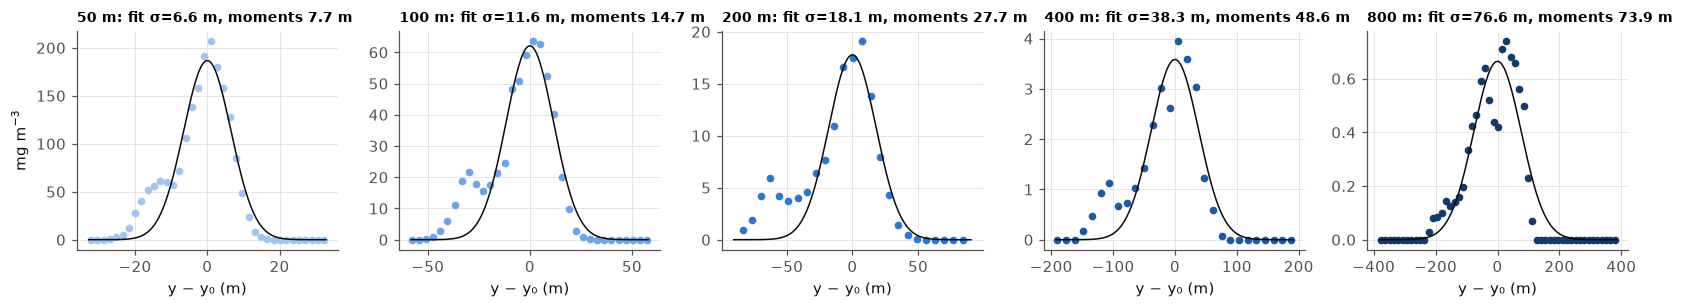

In [2]:
def gauss(y, A, y0, s):
    return A * np.exp(-(y - y0) ** 2 / (2 * s ** 2))

def crosswind(run, arc):
    d = arcs[(arcs.run == run) & (arcs.arc_m == arc) & arcs.status.isin(["value", "not_measurable"])].sort_values("post")
    return arc * np.deg2rad(d.bearing_unwrapped.to_numpy(float)), d.concentration_mg_m3.fillna(0).to_numpy(float)

RUN = "33"
fig, axes = plt.subplots(1, 5, figsize=(15, 2.9))
for ax, arc in zip(axes, pgdata.ARCS_M):
    y, c = crosswind(RUN, arc)
    w = c / c.sum(); y0 = (w * y).sum(); s0 = np.sqrt((w * (y - y0) ** 2).sum())
    (A, y0, s), _ = curve_fit(gauss, y, c, p0=[c.max(), y0, s0], maxfev=5000)
    near = np.abs(y - y0) < 5 * abs(s)
    ax.plot(y[near] - y0, c[near], "o", ms=4, color=pgdata.ARC_COLORS[arc])
    yy = np.linspace(-5 * abs(s), 5 * abs(s), 200); ax.plot(yy, gauss(yy, A, 0, s), color=pgdata.INK, lw=1)
    sy = summ.query("run == @RUN and arc_m == @arc").sigma_y_m.iloc[0]
    ax.set_title(f"{arc} m: fit σ={abs(s):.1f} m, moments {sy:.1f} m", fontsize=9); ax.set_xlabel("y − y₀ (m)")
axes[0].set_ylabel("mg m$^{-3}$"); plt.tight_layout(); plt.show()

Close to Gaussian, with slightly heavy tails. The fitted and moment widths agree, and the
moment width needs no fit, so we use it from here on.

### σ_y: growth with distance, and Taylor's theory

On the left, σ_y against distance, with the Briggs (1973) open-country curves for Pasquill
stability classes A (very unstable) to F (very stable) dotted. On the right is a test of G. I.
Taylor's (1921) result: near the source the plume width is just the swing of the wind times
the distance, σ_y ≈ σ_θ·x. The wind vane and the samplers are independent instruments, so the
agreement is a real test.

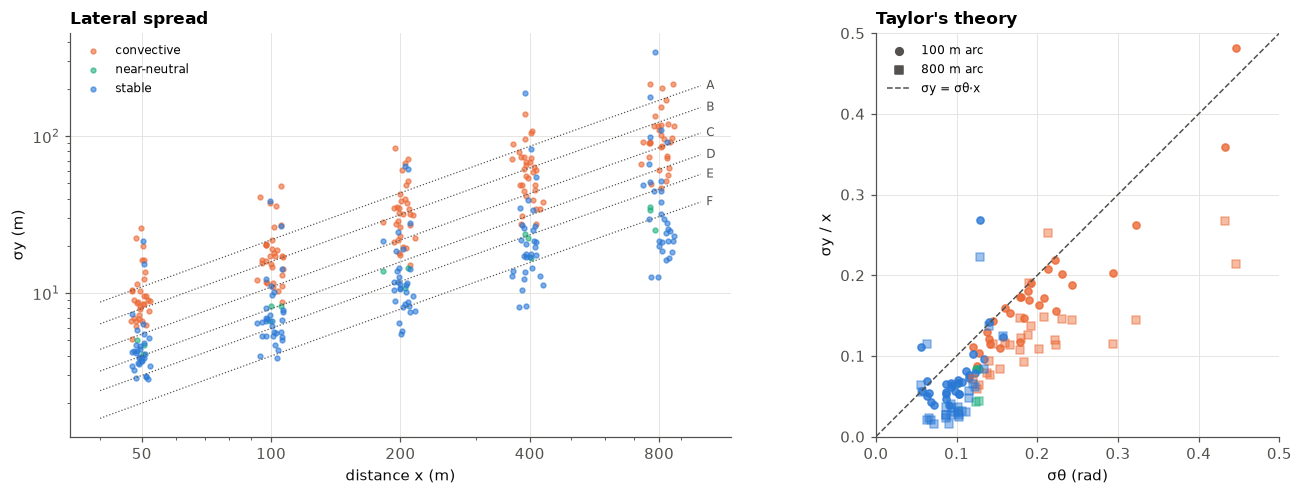

In [3]:
x = np.geomspace(40, 1000, 50)
BRIGGS_Y = {c: k for c, k in zip("ABCDEF", [.22, .16, .11, .08, .06, .04])}
sigma_y_briggs = lambda cls, x: BRIGGS_Y[cls] * x / np.sqrt(1 + 1e-4 * x)

fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 4.6))
for reg, g in summ.dropna(subset=["regime", "sigma_y_m"]).groupby("regime", observed=True):
    ax.scatter(g.arc_m * jitter(len(g)), g.sigma_y_m, s=10, alpha=0.6, color=colors[reg], label=reg)
for cls in "ABCDEF":
    ax.plot(x, sigma_y_briggs(cls, x), color=pgdata.MUTED, lw=0.8, ls=":")
    ax.text(1030, sigma_y_briggs(cls, 1000), cls, color=pgdata.MUTED, fontsize=8, va="center")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(pgdata.ARCS_M, pgdata.ARCS_M)
ax.set_xlabel("distance x (m)"); ax.set_ylabel("σy (m)"); ax.legend(fontsize=8); ax.set_title("Lateral spread")

for arc, mk in [(100, "o"), (800, "s")]:
    d = summ[summ.arc_m == arc].dropna(subset=["sigma_theta_source_10", "regime"])
    for reg, g in d.groupby("regime", observed=True):
        bx.scatter(np.deg2rad(g.sigma_theta_source_10), g.sigma_y_m / arc, color=colors[reg], s=22, marker=mk,
                   alpha=0.8 if arc == 100 else 0.45)
    bx.scatter([], [], color=pgdata.MUTED, marker=mk, label=f"{arc} m arc")
bx.plot([0, 0.5], [0, 0.5], color=pgdata.MUTED, ls="--", lw=1, label="σy = σθ·x")
bx.set_xlim(0, .5); bx.set_ylim(0, .5); bx.set_aspect("equal")
bx.set_xlabel("σθ (rad)"); bx.set_ylabel("σy / x"); bx.legend(fontsize=8); bx.set_title("Taylor's theory")
plt.tight_layout(); plt.show()

Convective plumes follow the Pasquill A–C curves and stable ones D–F. In the Taylor test the
100 m points sit on the 1:1 line. By 800 m they fall below it: the plume has grown larger than
the eddies that swing it, so it no longer moves sideways as a whole. That slowing is what the
√(1 + 10⁻⁴x) factor in the Briggs curves represents.

### σ_z from mass conservation, checked against the towers

There is no vertical profile on most arcs, but mass conservation gives σ_z anyway. All the gas
released must cross each arc, so integrating the Gaussian across the plume at the ground gives

$$ C_y = \int C\,dy = \frac{2Q}{\sqrt{2\pi}\,u\,\sigma_z} \quad\Rightarrow\quad \sigma_z = \sqrt{\tfrac{2}{\pi}}\,\frac{Q}{u\,C_y}. $$

At 100 m the towers measure the vertical profile directly. For a ground-level Gaussian, ln C is
linear in z², with slope −1/(2σ_z²). Two independent routes to the same number:

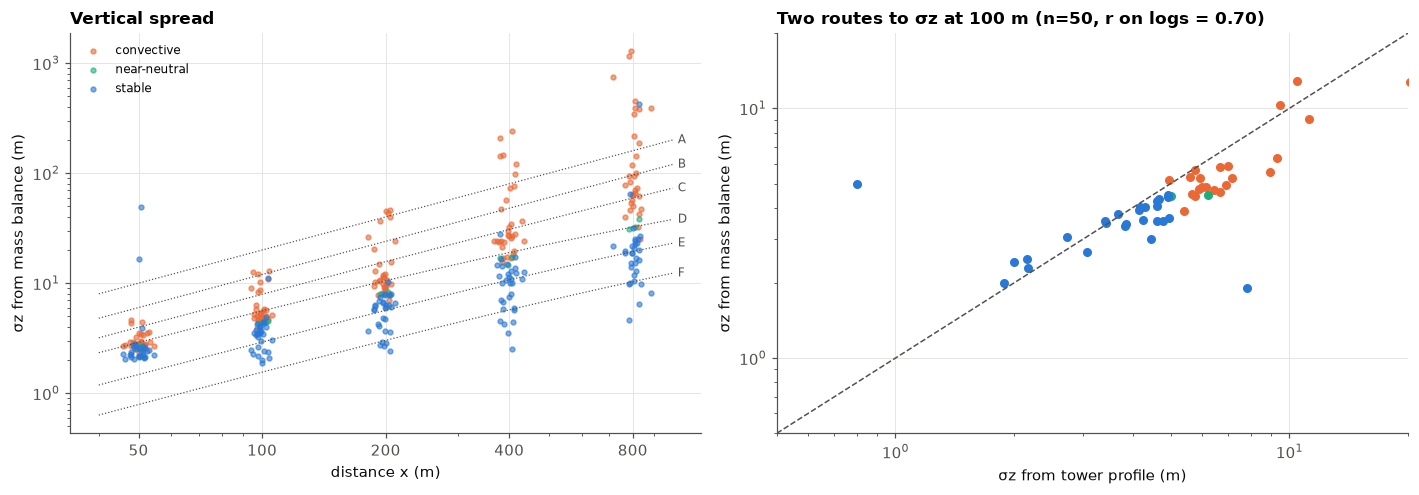

In [4]:
summ["sigma_z_mb"] = np.sqrt(2 / np.pi) * summ.Q_g_s / (summ.u_ref * summ.cwic / 1000)

def tower_sigma_z(run):
    d = towers[(towers.run == run) & (towers.status == "value") & (towers.concentration_mg_m3 > 0)]
    d = d[d.groupby("tower").height_m.transform("size") >= 3]
    if d.empty:
        return np.nan
    X = np.column_stack([d.height_m ** 2] + [(d.tower == t).astype(float) for t in sorted(d.tower.unique())])
    coef, *_ = np.linalg.lstsq(X, np.log(d.concentration_mg_m3), rcond=None)   # one intercept per tower
    return np.sqrt(-1 / (2 * coef[0])) if coef[0] < 0 else np.nan

BRIGGS_Z = {"A": lambda x: .20 * x, "B": lambda x: .12 * x, "C": lambda x: .08 * x / np.sqrt(1 + 2e-4 * x),
            "D": lambda x: .06 * x / np.sqrt(1 + 1.5e-3 * x), "E": lambda x: .03 * x / (1 + 3e-4 * x),
            "F": lambda x: .016 * x / (1 + 3e-4 * x)}
fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 4.6))
for reg, g in summ.dropna(subset=["regime", "sigma_z_mb"]).groupby("regime", observed=True):
    ax.scatter(g.arc_m * jitter(len(g), 1), g.sigma_z_mb, s=10, alpha=0.6, color=colors[reg], label=reg)
for cls, f in BRIGGS_Z.items():
    ax.plot(x, f(x), color=pgdata.MUTED, lw=0.8, ls=":"); ax.text(1030, f(1000), cls, color=pgdata.MUTED, fontsize=8, va="center")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(pgdata.ARCS_M, pgdata.ARCS_M)
ax.set_xlabel("distance x (m)"); ax.set_ylabel("σz from mass balance (m)"); ax.legend(fontsize=8); ax.set_title("Vertical spread")

tw = pd.Series({r: tower_sigma_z(r) for r in towers.run.unique()}, name="sigma_z_tower")
cmp = summ[summ.arc_m == 100].set_index("run")[["sigma_z_mb", "regime"]].join(tw, how="inner").dropna()
for reg, g in cmp.groupby("regime", observed=True):
    bx.scatter(g.sigma_z_tower, g.sigma_z_mb, color=colors[reg], s=24, label=reg)
lim = [0.5, 20]; bx.plot(lim, lim, color=pgdata.MUTED, ls="--", lw=1)
bx.set_xscale("log"); bx.set_yscale("log"); bx.set_xlim(lim); bx.set_ylim(lim)
r = np.corrcoef(np.log(cmp.sigma_z_tower), np.log(cmp.sigma_z_mb))[0, 1]
bx.set_xlabel("σz from tower profile (m)"); bx.set_ylabel("σz from mass balance (m)")
bx.set_title(f"Two routes to σz at 100 m (n={len(cmp)}, r on logs = {r:.2f})"); plt.tight_layout(); plt.show()

At 100 m the two estimates agree for most runs, from shallow stable plumes to deep convective
ones, with a few outliers. Further out the mass balance breaks down for convective runs (σ_z of
hundreds of metres at 800 m is not physical): it divides by the 2 m wind, while a deep plume
rides faster air aloft, and an arc that misses part of the plume under-counts C_y.

## 2. The textbook model, with no fitting

Now the model regulators would have used. No parameter is fitted to this data:

1. **Stability class from σθ**, the U.S. EPA's lateral-turbulence method: σθ ≥ 22.5° → A,
   17.5° → B, 12.5° → C, 7.5° → D, 3.75° → E, below that F. (The method is meant for a 10 m
   vane; we only have 2 m, a first caveat.)
2. **σ_y, σ_z from the Briggs curves** for that class.
3. **Gaussian plume** at the samplers: on the plume centreline, z = 1.5 m, source h = 0.46 m.

We predict the peak C·u/Q on each arc, which removes the release rate and the first-order wind
effect. The scores are those used to benchmark dispersion models:

| Score | Meaning | Perfect |
|---|---|---|
| FAC2 | share of predictions within a factor of 2 of the observation | 1 |
| MG | geometric mean bias, exp(mean ln(obs/pred)); > 1 under-predicts | 1 |
| FB | fractional bias of the means; > 0 under-predicts | 0 |
| NMSE | normalised mean square error | 0 |

A FAC2 of about 0.5 is commonly taken as acceptable for a dispersion model in the field.

In [5]:
def pasquill_class(sigma_theta_deg):
    for cls, lower in zip("ABCDE", [22.5, 17.5, 12.5, 7.5, 3.75]):
        if sigma_theta_deg >= lower:
            return cls
    return "F" if pd.notna(sigma_theta_deg) else None

def gaussian_peak(cls, x, z=1.5, h=pgdata.SOURCE_HEIGHT_M):
    """Centreline C·u/Q (m^-2) for a point source at h, receptor at z."""
    sy, sz = sigma_y_briggs(cls, x), BRIGGS_Z[cls](x)
    return (np.exp(-(z - h) ** 2 / (2 * sz ** 2)) + np.exp(-(z + h) ** 2 / (2 * sz ** 2))) / (2 * np.pi * sy * sz)

def scores(obs, pred):
    o, p = np.asarray(obs, float), np.asarray(pred, float)
    return pd.Series({"n": len(o), "FAC2": np.mean((p / o >= 0.5) & (p / o <= 2)), "MG": np.exp(np.mean(np.log(o / p))),
                      "FB": 2 * (o.mean() - p.mean()) / (o.mean() + p.mean()),
                      "NMSE": ((o - p) ** 2).mean() / (o.mean() * p.mean())})

m = summ[(summ.peak > 0) & summ.u_ref.notna() & summ.sigma_theta_source_10.notna() & summ.regime.notna()].copy()
m["obs"] = m.peak / 1000 * m.u_ref / m.Q_g_s                  # mg -> g; C·u/Q in m^-2
m["cls"] = m.sigma_theta_source_10.map(pasquill_class)
m["textbook"] = [gaussian_peak(c, x) for c, x in zip(m.cls, m.arc_m)]
print(f"{m.run.nunique()} runs, {len(m)} run-arc pairs;  classes:", m.drop_duplicates("run").cls.value_counts().sort_index().to_dict())
pd.concat({"all arcs": scores(m.obs, m.textbook)} |
          {f"{a} m": scores(g.obs, g.textbook) for a, g in m.groupby("arc_m")}, axis=1).T.round(2)

61 runs, 305 run-arc pairs;  classes: {'A': 2, 'B': 1, 'C': 5, 'D': 20, 'E': 29, 'F': 4}


,n,FAC2,MG,FB,NMSE
all arcs,305.0,0.75,0.83,-0.21,0.51
50 m,61.0,0.92,0.72,-0.30,0.20
100 m,61.0,0.85,0.79,-0.15,0.29
200 m,61.0,0.85,0.90,0.10,0.47
400 m,61.0,0.66,0.89,0.30,1.17
800 m,61.0,0.48,0.88,0.55,2.71


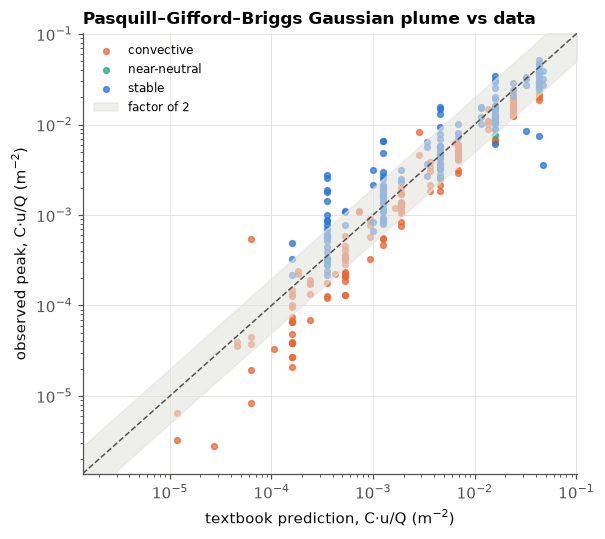

In [6]:
fig, ax = plt.subplots(figsize=(5.8, 5.2))
for reg, g in m.groupby("regime", observed=True):
    ax.scatter(g.textbook, g.obs, s=14, color=colors[reg], alpha=0.75, label=reg)
lim = np.array([m[["obs", "textbook"]].min().min() / 2, m[["obs", "textbook"]].max().max() * 2])
ax.plot(lim, lim, color=pgdata.MUTED, ls="--", lw=1)
ax.fill_between(lim, lim / 2, lim * 2, color=pgdata.GRID, alpha=0.6, label="factor of 2")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("textbook prediction, C·u/Q (m$^{-2}$)"); ax.set_ylabel("observed peak, C·u/Q (m$^{-2}$)")
ax.set_title("Pasquill–Gifford–Briggs Gaussian plume vs data"); ax.legend(fontsize=8); plt.show()

A one-line stability class and two textbook curves land about **three quarters** of all
predictions within a factor of 2, with no fitting. It works best near the source (50–200 m). At
800 m it degrades and over-predicts some plumes badly: the Briggs curves were never tuned for a
plume this close to the ground, and a single σθ from a 2 m vane at the source says little about
the turbulence 800 m away.

## 3. Learning from the data

Can a model fitted to the data do better? Four candidates, all predicting log₁₀(C·u/Q):

- **two-regime regression**: a straight line in log x, with its own intercept and slope for stable runs (4 parameters);
- **σθ regression**: a straight line in log x and log σθ, with their interaction (4 parameters), physics-motivated by Taylor's σ_y ∝ σθ·x;
- **gradient boosting** on distance and six weather inputs (σθ, wind, Ri, ΔT, u*, net radiation): generic machine learning;
- **hybrid**: the textbook model, plus gradient boosting trained to correct its errors.

**Validation must not leak.** The five arcs of one run share the same weather, so a random split
of rows would let the model see the test run's weather. We use **leave-one-run-out**: each run's
arcs are predicted by a model trained on all the other runs.

In [7]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict

m["y"], m["lx"] = np.log10(m.obs), np.log10(m.arc_m)
m["lst"], m["stable"] = np.log10(m.sigma_theta_source_10), (m.regime == "stable").astype(float)
weather = ["sigma_theta_source_10", "u_ref", "Ri_b", "dT_16_05", "u_star", "rad_net_radiation"]
logo = LeaveOneGroupOut()

def loro_ols(design):
    pred = pd.Series(index=m.index, dtype=float)
    for run in m.run.unique():
        tr = m.run != run
        coef, *_ = np.linalg.lstsq(design(m[tr]), m.y[tr], rcond=None)
        pred[~tr] = design(m[~tr]) @ coef
    return 10 ** pred

gbm = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=8,
                                            min_samples_leaf=10, random_state=0)
pred = {
    "textbook (no fit)": m.textbook,
    "two-regime regression": loro_ols(lambda d: np.column_stack([np.ones(len(d)), d.lx, d.stable, d.stable * d.lx])),
    "σθ regression": loro_ols(lambda d: np.column_stack([np.ones(len(d)), d.lx, d.lst, d.lst * d.lx])),
    "gradient boosting": 10 ** cross_val_predict(gbm(), m[["lx"] + weather], m.y, groups=m.run, cv=logo),
    "hybrid (textbook + boosting)": m.textbook * 10 ** cross_val_predict(gbm(), m[["lx"] + weather], m.y - np.log10(m.textbook),
                                                                          groups=m.run, cv=logo),
}
pd.DataFrame({k: scores(m.obs, p) for k, p in pred.items()}).T.round(2)

,n,FAC2,MG,FB,NMSE
textbook (no fit),305.0,0.75,0.83,-0.21,0.51
two-regime regression,305.0,0.72,1.00,0.06,0.43
σθ regression,305.0,0.92,1.00,0.01,0.43
gradient boosting,305.0,0.92,0.97,0.00,0.21
hybrid (textbook + boosting),305.0,0.87,0.98,-0.02,0.33


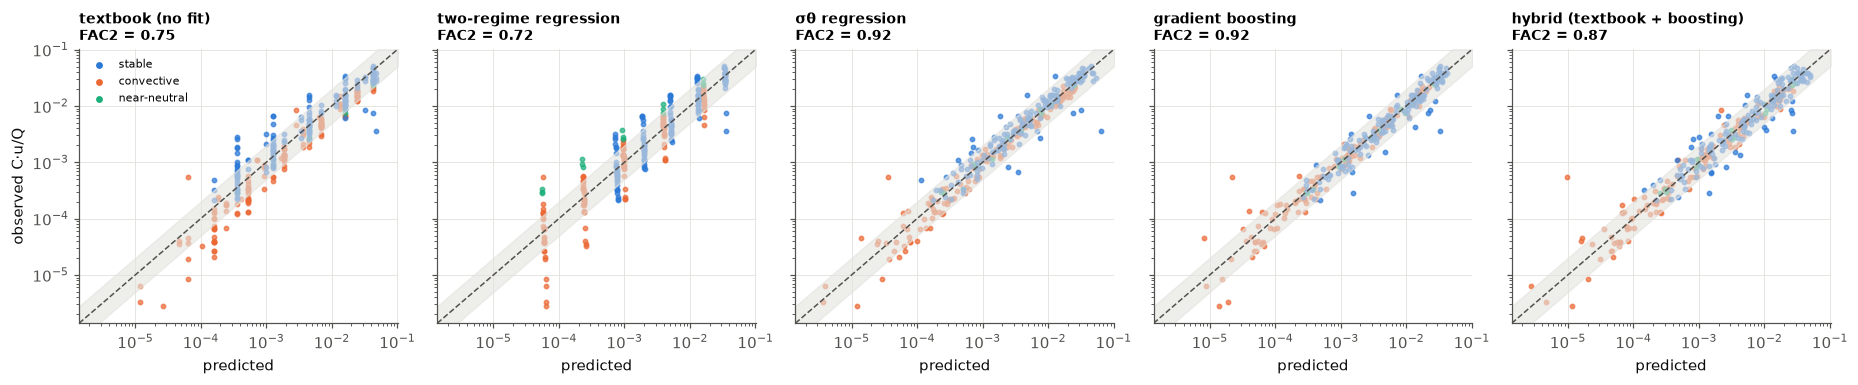

In [8]:
fig, axes = plt.subplots(1, len(pred), figsize=(17, 3.6), sharex=True, sharey=True)
for ax, (name, p) in zip(axes, pred.items()):
    for reg, g in m.groupby("regime", observed=True):
        ax.scatter(np.asarray(p)[m.index.get_indexer(g.index)], g.obs, s=8, color=colors[reg], alpha=0.7)
    ax.plot(lim, lim, color=pgdata.MUTED, ls="--", lw=1); ax.fill_between(lim, lim / 2, lim * 2, color=pgdata.GRID, alpha=0.6)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{name}\nFAC2 = {scores(m.obs, p).FAC2:.2f}", fontsize=9); ax.set_xlabel("predicted")
for reg, c in colors.items():
    axes[0].scatter([], [], color=c, s=12, label=reg)
axes[0].legend(fontsize=7, loc="upper left"); axes[0].set_ylabel("observed C·u/Q"); plt.tight_layout(); plt.show()

**What this shows**

- The **two-regime** switch is no better than the textbook model, despite being fitted: day
  against night is far too coarse a description of the atmosphere.
- **Gradient boosting** on six weather inputs and the **four-parameter σθ regression** tie, with
  over 90 % of predictions within a factor of 2. One well-chosen physical variable, the gustiness of
  the wind as Taylor's theory suggests, does as well as a flexible learner. (Boosting has the
  lower NMSE, so it handles the extremes a little better.)
- The **hybrid** improves a lot on the textbook model but not on boosting alone. Here the
  textbook curves add little the data cannot learn by itself.
- With about 60 independent runs, the honest error bar on these scores is a few points of FAC2.
  Be wary of ranking models more finely than that.

Which inputs does the boosted model lean on? Permutation importance (on a model fitted to all
runs, so only indicative):

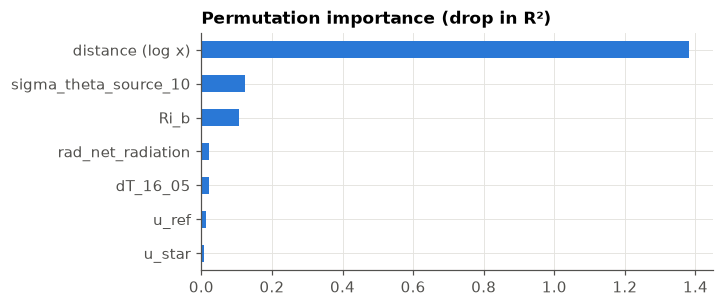

In [9]:
from sklearn.inspection import permutation_importance
model = gbm().fit(m[["lx"] + weather], m.y)
imp = permutation_importance(model, m[["lx"] + weather], m.y, n_repeats=10, random_state=0)
pd.Series(imp.importances_mean, index=["distance (log x)"] + weather).sort_values(ascending=False) \
    .plot.barh(figsize=(6, 2.8), color=pgdata.ARC_COLORS[200], title="Permutation importance (drop in R²)"); plt.gca().invert_yaxis(); plt.show()

Distance dominates, as it must. Among the weather inputs σθ comes first, as the regression suggested, with Ri close behind.

## Things to try

- `pgdata.arc_summary(corrected=True)` applies the Table 5.4 evaporation corrections to the
  concentrations. Does the fit at 800 m improve?
- Replace the σθ stability class with one from Ri or from ΔT (also standard methods) and compare FAC2.
- Use the 8 m wind instead of the 2 m wind for the long-range arcs.
- Fit a stretched exponential exp(−(z/ℓ)^s) to the tower profiles: Prairie Grass is known for s ≈ 1.5, not 2.
- Before trusting any single run, check `annotations.jsonl` (notebook 1): run 44 and run 10 at
  800 m contain suspected misprints.